In [4]:

!pip install --user tensorflow==2.15.0


  Obtaining dependency information for tensorflow==2.15.0 from https://files.pythonhosted.org/packages/93/21/9b035a4f823d6aee2917c75415be9a95861ff3d73a0a65e48edbf210cec1/tensorflow-2.15.0-cp311-cp311-win_amd64.whl.metadata
  Using cached tensorflow-2.15.0-cp311-cp311-win_amd64.whl.metadata (3.6 kB)
  Obtaining dependency information for tensorflow-intel==2.15.0 from https://files.pythonhosted.org/packages/4c/48/1a5a15517f18eaa4ff8d598b1c000300b20c1bb0e624539d702117a0c369/tensorflow_intel-2.15.0-cp311-cp311-win_amd64.whl.metadata
  Using cached tensorflow_intel-2.15.0-cp311-cp311-win_amd64.whl.metadata (5.1 kB)
  Obtaining dependency information for tensorboard<2.16,>=2.15 from https://files.pythonhosted.org/packages/37/12/f6e9b9dcc310263cbd3948274e286538bd6800fd0c268850788f14a0c6d0/tensorboard-2.15.2-py3-none-any.whl.metadata
  Using cached tensorboard-2.15.2-py3-none-any.whl.metadata (1.7 kB)
  Obtaining dependency information for keras<2.16,>=2.15.0 from https://files.pythonhosted.or

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


 Training LSTM on Zone 132 (Total Dense Rows: 8784)
 Training Sequences: 7008 | Testing Sequences: 1752
 Starting LSTM Training...
Epoch 1/5
110/110 [==============================] - 23s 71ms/step - loss: 0.0366 - val_loss: 0.0147
Epoch 2/5
110/110 [==============================] - 5s 44ms/step - loss: 0.0126 - val_loss: 0.0107
Epoch 3/5
110/110 [==============================] - 4s 41ms/step - loss: 0.0115 - val_loss: 0.0086
Epoch 4/5
110/110 [==============================] - 5s 42ms/step - loss: 0.0109 - val_loss: 0.0078
Epoch 5/5
55/55 [==============================] - 4s 14ms/step

 LSTM Neural Network RMSE: 0.0882


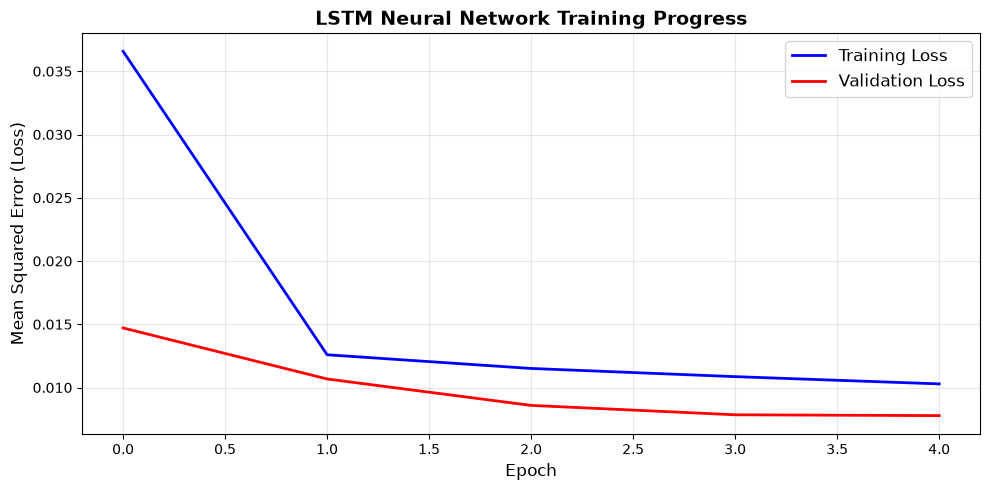

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.metrics import mean_squared_error
import os
import warnings
import tensorflow as tf

warnings.filterwarnings('ignore')
project_folder = r"C:\Users\Harshitha\Downloads\Project spy"

# 1. Load Data
merged_df = pd.read_parquet(os.path.join(project_folder, "final_features_2024.parquet"))

# 2. Select JFK (Zone 132)
top_zone = merged_df.groupby('zone_id')['demand_count'].sum().idxmax()
df_dl = merged_df[merged_df['zone_id'] == top_zone].copy()
df_dl['pickup_hour'] = pd.to_datetime(df_dl['pickup_hour'])

#  THE FIX: Create a continuous hourly timeline for the whole year
full_hours = pd.date_range(start='2024-01-01', end='2024-12-31 23:00:00', freq='H')
df_dl = df_dl.set_index('pickup_hour').reindex(full_hours).reset_index()
df_dl.rename(columns={'index': 'pickup_hour'}, inplace=True)

# Fill missing values (If no rides, demand = 0. Forward fill weather)
df_dl['demand_count'] = df_dl['demand_count'].fillna(0)
df_dl['HourlyDryBulbTemperature'] = df_dl['HourlyDryBulbTemperature'].ffill().bfill()
df_dl['HourlyPrecipitation'] = df_dl['HourlyPrecipitation'].fillna(0)
df_dl['hour'] = df_dl['pickup_hour'].dt.hour

print(f" Training LSTM on Zone {top_zone} (Total Dense Rows: {len(df_dl)})")

# 3. Scale features
features = ['demand_count', 'HourlyDryBulbTemperature', 'HourlyPrecipitation', 'hour']
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(df_dl[features])

# 4. Create Sequences
def create_sequences(data, seq_length):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length, :])
        y.append(data[i+seq_length, 0])
    return np.array(X), np.array(y)

seq_length = 24
X, y = create_sequences(scaled_data, seq_length)

# 5. Split (80% Train, 20% Test)
split_idx = int(len(X) * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

print(f" Training Sequences: {X_train.shape[0]} | Testing Sequences: {X_test.shape[0]}")

# 6. Build Model (with clipnorm to prevent NaN)
model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(1)
])

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, clipnorm=1.0)
model.compile(optimizer=optimizer, loss='mse')

print(" Starting LSTM Training...")
history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_data=(X_test, y_test), verbose=1)

# 7. Evaluate
predictions = model.predict(X_test)
rmse_lstm = np.sqrt(mean_squared_error(y_test, predictions))
print(f"\n LSTM Neural Network RMSE: {rmse_lstm:.4f}")

# 8. Plot
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss', color='blue', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss', color='red', linewidth=2)
plt.title('LSTM Neural Network Training Progress', fontsize=14, fontweight='bold')
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Mean Squared Error (Loss)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(project_folder, "week5_lstm_training.png"), dpi=150)
plt.show()